### De novo aptamer design using AptaDiff
Step-by-step guide for generating new aptamer sequences from raw SELEX reads.

### Overview

AptaDiff generates new aptamers from the reads of a SELEX experiment. It does not need labels and does not protein target (unsupervised), and learns directly from the sequences that survived selection.

Training happens in three stages: a pretrained variational autoencoder (VAE) maps each read to a point in a small latent space. A diffusion model learns to generate a read back from its own latent point. A Gaussian mixture is then fitted to those points, and new sequences are generated from it.

The classes used in this notebook:

* `MoleculeLoader`: lazy container for sequence data, cells may hold sequences or file paths, materialized with `to_dataframe()`.
* `PrimerTrimmer`: strips the constant primer regions of a SELEX read and keeps the random region.
* `CNNPHMMVAEFast`: the RaptGen VAE that supplies the latent coordinates.
* `AptaDiffGenerator`: trains the diffusion model and generates a sequence from a latent point.
* `AptaDiff`: the end-to-end estimator that ties these together, with `fit` and `sample`.

The data is `datasetD.fastq`, the SELEX library published with the AptaDiff paper.


In [1]:
import torch
from torch.utils.data import DataLoader, TensorDataset

from pyaptamer.aptadiff import AptaDiff, AptaDiffGenerator
from pyaptamer.data import MoleculeLoader
from pyaptamer.raptgen import CNNPHMMVAEFast
from pyaptamer.transformations.encode import SequenceOneHotEncoder
from pyaptamer.transformations.transform import PrimerTrimmer

### Settings

Training is sized to finish in a few minutes on a CPU.


In [2]:
# Data
DATA_PATH = "data_selex/datasetD.fastq"
READ_LENGTH = 100
N_READS = 20000  # subset of reads used for training, the full file holds 121,185

# SELEX library design
START_PRIMER = "TAATACGACTCACTATAGGGAGAACTTCGACCAGAAG"
END_PRIMER = "TATGTGCGCATACATGGATCCTC"
VARIABLE_LENGTH = 40

# VAE training (placeholder until RaptGen's training class merged, see Step 3)
VAE_EPOCHS = 3
VAE_BATCH = 64  # RaptGenModel's default
VAE_LR = 1e-3  # RaptGenModel's default
BETA_THRESHOLD = 2  # epochs over which the KL weight is annealed to 1.0


# Diffusion Model
DIM = 128
DEPTH = 4
NUM_TIMESTEPS = 100
MAX_EPOCHS = 8

# Latent space and clustering
EMBED_SIZE = 2
N_CLUSTERS = 8
GMM_RESTARTS = 100

RANDOM_STATE = 0

### Step 1: Load the SELEX reads

Every read follows the same library design: a constant 37-nt start primer, a 40-nt random region, then a constant 23-nt end primer. Reads that were truncated during sequencing are shorter than 100 nt, so we keep only the full-length ones.


In [3]:
loader = MoleculeLoader(data={"sequence": [DATA_PATH]}, tiling="samples")
reads = loader.to_dataframe()

print(f"{len(reads)} reads in the file")
reads.head()

121185 reads in the file


,sequence
0__JLBRL:00004:00007,TAATACGACTCACTATAGGGAGAACTTCGACCAGAAGATGAGCAGC...
0__JLBRL:00004:00022,TAATACGACTCACTATAGGGAGAACTTCGACCAGAAGGTTCAAATC...
0__JLBRL:00004:00046,TAATACGACTCACTATAGGGAATGCACTAGTGTTCAAAACACAGGT...
0__JLBRL:00004:00048,TAATACGACTCACTATAGGGAGAACTTCGACCAGAAGAAACCGTAA...
0__JLBRL:00005:00019,TAATACGACTCACTATAGGGAGAACTTCGACCAGAAGAGGCCCAAA...


In [4]:
reads["sequence"].str.len().value_counts().head(4)

sequence
100    61627
99     11479
101     9053
102     3624
Name: count, dtype: int64

In [5]:
X = reads[reads["sequence"].str.len() == READ_LENGTH].head(N_READS)

print(f"{len(X)} full-length reads selected")
X.head()

20000 full-length reads selected


,sequence
0__JLBRL:00004:00022,TAATACGACTCACTATAGGGAGAACTTCGACCAGAAGGTTCAAATC...
0__JLBRL:00004:00048,TAATACGACTCACTATAGGGAGAACTTCGACCAGAAGAAACCGTAA...
0__JLBRL:00005:00019,TAATACGACTCACTATAGGGAGAACTTCGACCAGAAGAGGCCCAAA...
0__JLBRL:00005:00038,TAATACGACTCACTATAGGGAGAACTTCGACCAGAAGTACCTTATC...
0__JLBRL:00005:00045,TAATACGACTCACTATAGGGAGAACTTCGACCAGAAGTCGCGCCTG...


### Step 2: Strip the primers

Only the random region is a candidate aptamer. `PrimerTrimmer` removes the two constant regions and drops any read that does not match the design, for example a read with a sequencing error inside a primer.


In [6]:
trimmer = PrimerTrimmer(
    start_primer=START_PRIMER,
    end_primer=END_PRIMER,
    variable_length=VARIABLE_LENGTH,
)

trimmed = trimmer.fit_transform(X)
trimmed.head()

[INFO] [_primer_trimmer] PrimerTrimmer dropped 1005 of 20000 reads that do not match the library design.


,sequence
0__JLBRL:00004:00022,GTTCAAATCCCCGCACATTACGTAACACTCGAACCCTACC
0__JLBRL:00004:00048,AAACCGTAAGACCGAGCGGCCCAGGTAAACCATACTTTCA
0__JLBRL:00005:00019,AGGCCCAAAGCCGCCACATTACGCGAAACTTCTTCCTCTC
0__JLBRL:00005:00038,TACCTTATCGCGTTACGTATAACACAGCCCTACCTACGCG
0__JLBRL:00005:00045,TCGCGCCTGTTAAGGTCACAATAACATACTCGTTCTCTCG


### Step 3: Build the components

`AptaDiff` does not build its parts itself. The VAE, the trimmer and the diffusion generator are created separately and passed in, so each one can be configured independently or replaced.

The VAE supplies the latent coordinates the diffusion model is conditioned on, so it has to be trained before `AptaDiff` uses it.

> Note: The loop below is a **temporary placeholder**. RaptGen does not yet ship a training class on `main`. Once PR #761 is merged it becomes a quick replacement, because `AptaDiff` only needs an object whose `transform` maps integer-encoded sequences to latent coordinates.

This notebook uses `CNNPHMMVAEFast`, not `CNNPHMMVAE`. The two share the same encoder, but the Fast variant's profile-HMM loss is about ten times faster per batch. The standard variant would take over ten minutes for a single epoch.

In [7]:
vae = CNNPHMMVAEFast(motif_len=VARIABLE_LENGTH, embed_size=EMBED_SIZE)

In [8]:
# The VAE is trained on the trimmed reads as integer indices, the same
# representation AptaDiff passes to vae.encoder internally.

onehot = SequenceOneHotEncoder(handle_unknown="drop").fit_transform(trimmed)
X_idx = (
    torch.as_tensor(onehot.to_numpy().copy())
    .reshape(len(onehot), 4, VARIABLE_LENGTH)
    .argmax(dim=1)
)

print(f"{len(X_idx)} reads encoded as {X_idx.shape[1]}-nt index vectors")

18995 reads encoded as 40-nt index vectors


In [9]:
torch.manual_seed(RANDOM_STATE)

optimizer = torch.optim.Adam(vae.parameters(), lr=VAE_LR)
loader = DataLoader(TensorDataset(X_idx), batch_size=VAE_BATCH, shuffle=True)

for epoch in range(1, VAE_EPOCHS + 1):
    # KL annealing: the weight of the KL term is raised over the first epochs
    beta = min(1.0, epoch / BETA_THRESHOLD)
    vae.train()
    total = 0.0
    for (batch,) in loader:
        optimizer.zero_grad()
        loss = vae.loss_fn(batch, *vae(batch), beta=beta)
        loss.backward()
        optimizer.step()
        total += loss.item() * batch.shape[0]
    print(f"epoch {epoch}/{VAE_EPOCHS}  beta={beta:.2f}  loss={total / len(X_idx):.3f}")

vae.eval()

epoch 1/3  beta=0.50  loss=55.734
epoch 2/3  beta=1.00  loss=53.711
epoch 3/3  beta=1.00  loss=53.510


CNNPHMMVAEFast(
  (encoder): EncoderCNN(
    (embed): Embedding(7, 32)
    (blocks): Sequential(
      (0): InvertedBottleneck(
        (conv1): Conv1d(32, 64, kernel_size=(1,), stride=(1,))
        (conv2): Conv1d(64, 64, kernel_size=(7,), stride=(1,), padding=(3,))
        (conv3): Conv1d(64, 32, kernel_size=(1,), stride=(1,))
        (bn1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (bn2): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (bn3): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      )
      (1): InvertedBottleneck(
        (conv1): Conv1d(32, 64, kernel_size=(1,), stride=(1,))
        (conv2): Conv1d(64, 64, kernel_size=(7,), stride=(1,), padding=(3,))
        (conv3): Conv1d(64, 32, kernel_size=(1,), stride=(1,))
        (bn1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
   

In [10]:
generator = AptaDiffGenerator(
    num_timesteps=NUM_TIMESTEPS,
    dim=DIM,
    depth=DEPTH,
    max_epochs=MAX_EPOCHS,
    random_state=RANDOM_STATE,
    # verbose=1, # shows train_loss/val_loss per epoch in a Lightning progress bar.
)

### Step 4: Fit

`fit` trims and encodes the reads, reads their latent coordinates out of the VAE, trains the diffusion model, and fits the Gaussian mixture. With the settings above this takes roughly three to four minutes on a CPU.

In [11]:
aptadiff = AptaDiff(
    vae=vae,
    trimmer=trimmer,
    generator=generator,
    n_clusters=N_CLUSTERS,
    gmm_restarts=GMM_RESTARTS,
    random_state=RANDOM_STATE,
)

aptadiff.fit(X)

[INFO] [_primer_trimmer] PrimerTrimmer dropped 1005 of 20000 reads that do not match the library design.
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/Users/aditi/miniconda3/envs/apt-dev/lib/python3.11/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/aditi/miniconda3/envs/apt-dev/lib/python3.11/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.
/Users/aditi/miniconda3/envs/apt-de

,vae,"CNNPHMMVAEFas..., bias=True) )"
,trimmer,PrimerTrimmer...ble_length=40)
,encoder,None
,n_clusters,8
,gmm_restarts,100
,generator,AptaDiffGener...andom_state=0)
,random_state,0
,num_classes,4
,num_timesteps,100
,dim,128
,depth,4


In [12]:
print("sequences kept: ", aptadiff.sequences_.shape)
print("latent coordinates: ", aptadiff.latents_.shape)
print("sequence length: ", aptadiff.seq_len_)
print("cluster centers: ", aptadiff.gmm_centers_.shape)

sequences kept:  (18995, 1)
latent coordinates:  (18995, 2)
sequence length:  40
cluster centers:  (8, 2)


### Step 5: Generate new sequences

`sample` draws latent points from the fitted mixture and generates one sequence per point. There is no `predict`. AptaDiff is generative, so new sequences come from `sample`.

In [13]:
aptadiff.sample(10)

,sequence
0,TTAACGCAACTACGCGATCAACTCGCCTCCCTCCCCTGCC
1,CCGCCTGCTGGTAAGTATCCACTGCTCCTCTTCGGCAGAG
2,ACCGTGATGTTGGCTTCTCACGTCCAGTGCGATCCCTATG
3,CCTAATGGCAGCATACATCTGTAGCCGGTGCACTCCTCGC
4,CGTAGGGCTTCAAGCCATCCCCCTCATTCTTAACTGACCA
5,TTGCTCACATTCATCGGCTCTTCAGTTGCACCCTCCTGCT
6,AAGGCCAGCCACAAACCCTCCCAAACTTCCCTCGTAAGTC
7,GGCAGTACACTTAAAGCTCACCCCAGCGGCGCCTCTCTCG
8,GATTAACGCGGTCGAGAAAGGACTGTTATGTGCTCTCTAC
9,TACCCTCGACCCCGCAACCTGTGTCTTGTCTCCCTTTAAT


### Step 6: Design from the cluster centers

The mixture components mark the dense regions of the latent space. Generating from the component means, instead of from random draws, is the de novo design procedure used in the original paper. `inverse_transform` accepts any latent points, including ones proposed by an outer optimisation loop such as Bayesian optimisation over wet-lab results.

In [14]:
aptadiff.inverse_transform(aptadiff.gmm_centers_)

,sequence
0,CAAAAGTCTCGGGGCACAATACATAACAACTGTCCCTACT
1,TGGGATAGAGCCTGGCCCGAGACTCAAGCCCCCGTATCCA
2,TTCGTGGGTGAGCAGCCTACCCAGCGCGGGCTCTTGTTTT
3,CAAACAGCGCGTTACTTTCGCTTCCCCAAGCTCAGCCGCC
4,TTTCCCACCGTCTCATATTTCGATCCTCACAAACCCTTCC
5,CTCAACATGCGCCAATACTCATGCCTTGCTCCCGCCTAAT
6,TTTATATTCTCCAAACACCCCCTTGGCTCAGCTTGGCTTG
7,TGCTACCGTCCTAAACATTAGCGGGGCGCCGCTGACTCTT


### Step 7: Visualization of Cluster (Optional)

`EMBED_SIZE` is 2, so the latent space can be plotted directly. Each grey point is one training read, each numbered blue point is a mixture component. `sample` draws from the mixture, so these centers are the regions new sequences are generated from.

This cell is skipped if matplotlib is not installed, since it is not a dependency of `pyaptamer`.

In [17]:
%pip install matplotlib

  Using cached matplotlib-3.11.2-cp311-cp311-macosx_11_0_arm64.whl.metadata (80 kB)
  Using cached contourpy-1.3.3-cp311-cp311-macosx_11_0_arm64.whl.metadata (5.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.5.1-cp311-cp311-macosx_11_0_arm64.whl.metadata (5.2 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached matplotlib-3.11.2-cp311-cp311-macosx_11_0_arm64.whl (9.3 MB)
Using cached contourpy-1.3.3-cp311-cp311-macosx_11_0_arm64.whl (270 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 13.9 MB/s  0:00:00 eta 0:00:01
Using cached kiwisolver-1.5.1-cp311-cp311-macosx_11_0_arm64.whl (64 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 13.3 MB/s  0:00:00 eta 0:00:01
Using cached pyparsing-3.3.3-py3-none-any.whl (126 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib]7 [matplotlib]
Note: you may need to restart the kernel to us

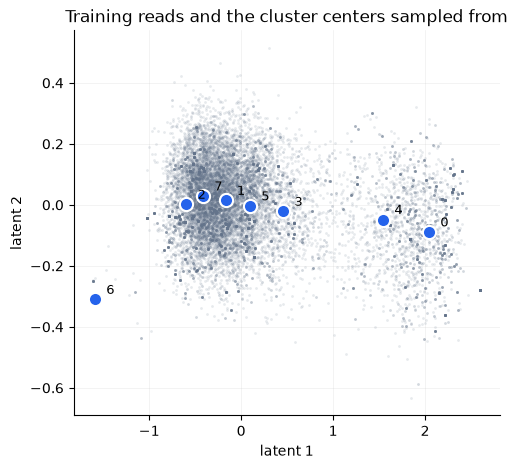

In [18]:
try:
    import matplotlib.pyplot as plt
except ImportError:
    plt = None
    print("matplotlib is not installed, `pip install matplotlib` to see this plot")

if plt is not None:
    fig, ax = plt.subplots(figsize=(5.5, 5))

    ax.scatter(
        aptadiff.latents_[:, 0],
        aptadiff.latents_[:, 1],
        s=4,
        alpha=0.15,
        color="#64748b",
        linewidths=0,
    )
    ax.scatter(
        aptadiff.gmm_centers_[:, 0],
        aptadiff.gmm_centers_[:, 1],
        s=90,
        color="#2563eb",
        edgecolor="white",
        linewidth=1.5,
        zorder=3,
    )
    for i, (x, y) in enumerate(aptadiff.gmm_centers_):
        ax.annotate(
            str(i), (x, y), xytext=(8, 4), textcoords="offset points", fontsize=9
        )

    ax.set_xlabel("latent 1")
    ax.set_ylabel("latent 2")
    ax.set_title("Training reads and the cluster centers sampled from")
    ax.grid(alpha=0.2, linewidth=0.5)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    plt.show()

### Step 8: Score sequences

`score` reports the average log-likelihood of sequences in bits per character, negated so that higher is better. It is a quick way to compare runs, for example after training the VAE for more epochs.

In [16]:
print("bits per character:", aptadiff.score(X.head(500)))
aptadiff.score_samples(X.head(5))

[INFO] [_primer_trimmer] PrimerTrimmer dropped 29 of 500 reads that do not match the library design.


bits per character: -1.828069806098938


array([-1.6965433, -1.7175912, -1.793976 , -1.9986448, -2.0882528],
      dtype=float32)